# F3.7 — Mapas de atribución: resumen descriptivo

Figuras de apoyo de la tarea F3.7 (`docs/bitacora/F3.7.md`, matriz §8 y Enmienda 3). Los 30 `.npz` de mapas (≈ 1.3 GiB) viven en el *dataset* privado `tt2-mapas`. Este notebook usa solo el resumen versionado que `src/interpretability/summarize_maps.py` calculó sobre ellos en Kaggle:

- `results/f37_mapas/resumen/per_run.csv`: mapas constantes, entropía, concentración y correlaciones, por corrida y tipo de mapa;
- `results/f37_mapas/resumen/class_means.npz`: mapa medio normalizado por split y clase real, en una rejilla de 56 × 56.

**Es descriptivo.** La agregación por clase en marco canónico, el perfil radial, la ablación espectral y las pruebas de cordura formales son de F4.3 (SV). Aquí solo se comprueba que los mapas no son degenerados y se muestra cómo se comparan el modelo real, su control permutado (F3.6) y la atención del *backbone*.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))
from viz import style

style.apply()
RES = REPO / 'results' / 'f37_mapas'
FIG = RES / 'figures'
TECHS = ['gray_scott', 'perlin', 'lorenz']
SEEDS = [42, 7, 123, 2024, 99]
STEM = {'gray_scott': 'gray_scott__efficientnet_b0__finetune__px224-flip',
        'perlin': 'perlin__vit_b16__frozen__px224-noflip', 'lorenz': 'lorenz__vit_b16__frozen__px224-noflip'}
METHOD = {'gray_scott': 'Grad-CAM', 'perlin': 'rollout ponderado', 'lorenz': 'rollout ponderado'}

## Insumos

Se verifica que el resumen cubre las 30 corridas de `records/`, que cada `.npz` resumido tiene la huella de su registro (`summarize_maps` lo comprobó en Kaggle; aquí se compara el log con los registros) y que la verificación del *dataset* dio 30/30.

In [2]:
recs = {json.loads(p.read_text(encoding='utf-8'))['run']: json.loads(p.read_text(encoding='utf-8'))
        for p in sorted((RES / 'records').glob('*.json'))}
ver = json.loads((RES / 'mapas_verificacion.json').read_text(encoding='utf-8'))
assert len(recs) == 30 and ver['passed'] and ver['n_ok'] == 30 and not ver['ambiguous']
by_file = {f['file']: f['sha256'] for f in ver['files']}
assert all(by_file[r['run'] + '.npz'] == r['npz']['sha256'] for r in recs.values())
per = pd.read_csv(RES / 'resumen' / 'per_run.csv')
assert set(per.run) == set(recs) and len(per) == 50          # 10 Grad-CAM + 20 ViT × 2 mapas
cm = np.load(RES / 'resumen' / 'class_means.npz')
assert len(cm.files) == 50 * 4
print(f"30 corridas; dataset verificado 30/30 ({len(ver['discarded_copies'])} copias de la prueba de humo descartadas)")
tabla = per.groupby(['technique', 'mapa', 'fase'], sort=False)[
    ['frac_constantes', 'entropia_media', 'masa_top10', 'corr_con_real', 'corr_con_backbone']].mean()
tabla.round(3)

30 corridas; dataset verificado 30/30 (20 copias de la prueba de humo descartadas)


frac_constantes  entropia_media  \
technique  mapa         fase                                                   
gray_scott map          control_permutacion            0.001          10.353   
                        final                          0.115          10.251   
lorenz     map          control_permutacion            0.000           9.962   
           backbone_map control_permutacion            0.000          11.057   
           map          final                          0.000           9.870   
           backbone_map final                          0.000          11.057   
perlin     map          control_permutacion            0.000          11.341   
           backbone_map control_permutacion            0.000          10.998   
           map          final                          0.000          11.379   
           backbone_map final                          0.000          10.998   

                                             masa_top10  corr_con_real  \
technique  mapa         fase                                             
gray_scott map          control_permutacion       0.448          0.230   
                        final                     0.464            NaN   
lorenz     map          control_permutacion       0.637          0.969   
           backbone_map control_permutacion       0.374          1.000   
           map          final                     0.658            NaN   
           backbone_map final                     0.374            NaN   
perlin     map          control_permutacion       0.252          0.795   
           backbone_map control_permutacion       0.377          1.000   
           map          final                     0.233            NaN   
           backbone_map final                     0.377            NaN   

                                             corr_con_backbone  
technique  mapa         fase                                    
gray_scott map          control_permutacion                NaN  
                        final                              NaN  
lorenz     map          control_permutacion              0.781  
           backbone_map control_permutacion                NaN  
           map          final                            0.758  
           backbone_map final                              NaN  
perlin     map          control_permutacion              0.193  
           backbone_map control_permutacion                NaN  
           map          final                            0.060  
           backbone_map final                              NaN

## Figura 1. Mapas medios por clase (modelos reales, prueba)

Por técnica, media de las cinco semillas de F3.5 del mapa normalizado sobre las muestras de prueba de cada clase real, y su diferencia (depresivo − no depresivo). En los ViT se muestra también la atención del *backbone*, que no depende de la cabeza. La escala es común dentro de cada fila; la diferencia usa una escala divergente centrada en 0.

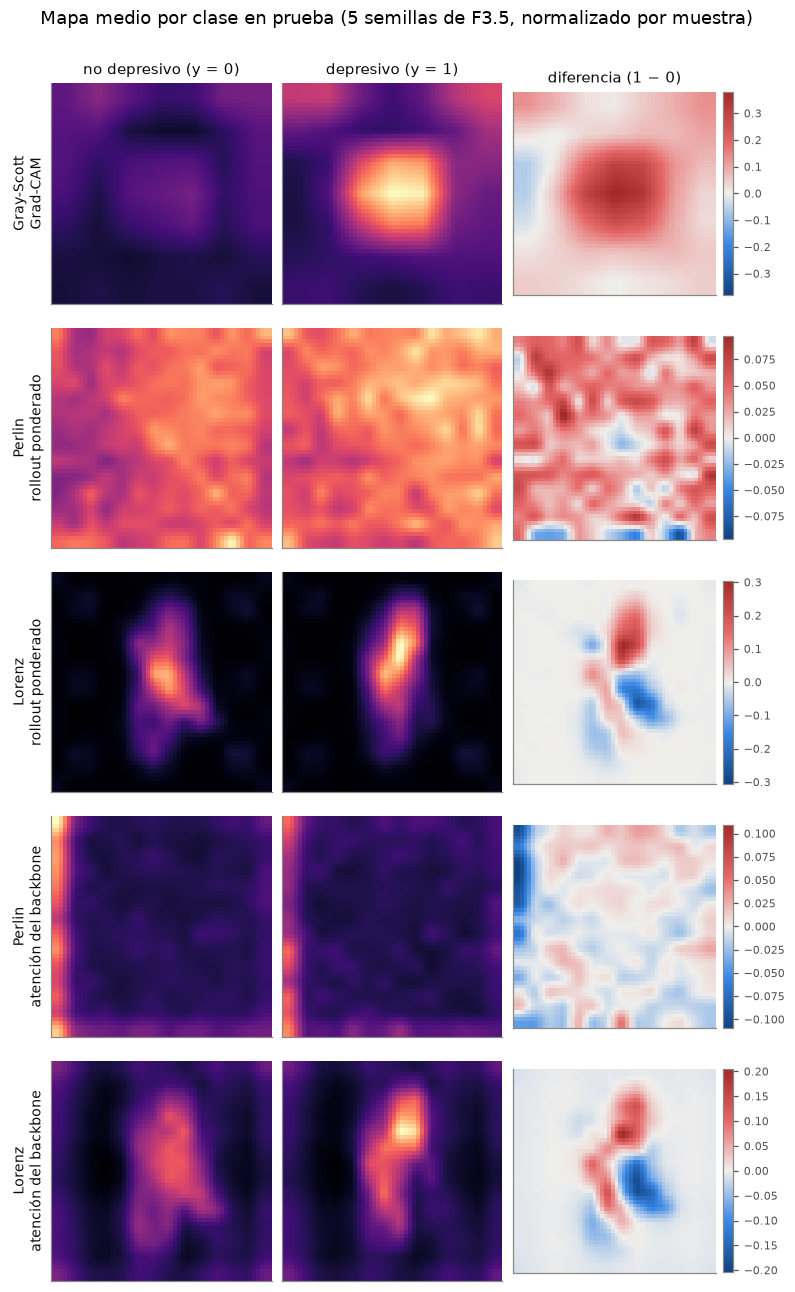

In [3]:
def key(tech, fase, s, mapa, split, y):
    stem = STEM[tech]
    if fase == 'control_permutacion':
        stem = stem + '-perm99'
    return f'{stem}__seed{s}|{mapa}|{split}|y{y}'

def mean_map(tech, fase, mapa, split, y):
    return np.mean([cm[key(tech, fase, s, mapa, split, y)] for s in SEEDS], axis=0)

rows = [(t, 'map') for t in TECHS] + [(t, 'backbone_map') for t in ('perlin', 'lorenz')]
fig, axes = plt.subplots(len(rows), 3, figsize=(7.2, 2.35 * len(rows)))
for i, (tech, mapa) in enumerate(rows):
    m0, m1 = mean_map(tech, 'final', mapa, 'test', 0), mean_map(tech, 'final', mapa, 'test', 1)
    vmax = max(m0.max(), m1.max())
    for j, (m, t) in enumerate(((m0, 'no depresivo (y = 0)'), (m1, 'depresivo (y = 1)'))):
        ax = axes[i, j]
        ax.imshow(m, cmap='magma', vmin=0, vmax=vmax)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(t)
    d = m1 - m0
    lim = np.abs(d).max()
    im = axes[i, 2].imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    axes[i, 2].set_xticks([]); axes[i, 2].set_yticks([])
    if i == 0:
        axes[i, 2].set_title('diferencia (1 − 0)')
    cb = fig.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.03)
    cb.ax.tick_params(labelsize=style.FONT_SIZES['annot'])
    lab = METHOD[tech] if mapa == 'map' else 'atención del backbone'
    axes[i, 0].set_ylabel(f'{style.TECH_LABEL[tech]}\n{lab}', fontsize=style.FONT_SIZES['label'])
fig.suptitle('Mapa medio por clase en prueba (5 semillas de F3.5, normalizado por muestra)', y=1.0)
fig.tight_layout()
style.save(fig, FIG / 'mapas_medios_por_clase')
plt.show()

## Figura 2. ¿Cambia el mapa si el modelo aprendió etiquetas permutadas?

Correlación media, por muestra, entre el mapa del control permutado (F3.6) y el del modelo real de la misma técnica y semilla (F3.5), sobre las 228 muestras. Es el insumo de la prueba de cordura por aleatorización de datos de F4.3 (Adebayo et al., 2018). Un método que refleja lo que el modelo aprendió de las etiquetas debe dar una correlación baja; uno que refleja solo la imagen y el *backbone*, una correlación cercana a 1. La atención del *backbone* sirve de referencia, porque no depende de la cabeza: su correlación es 1 por construcción.

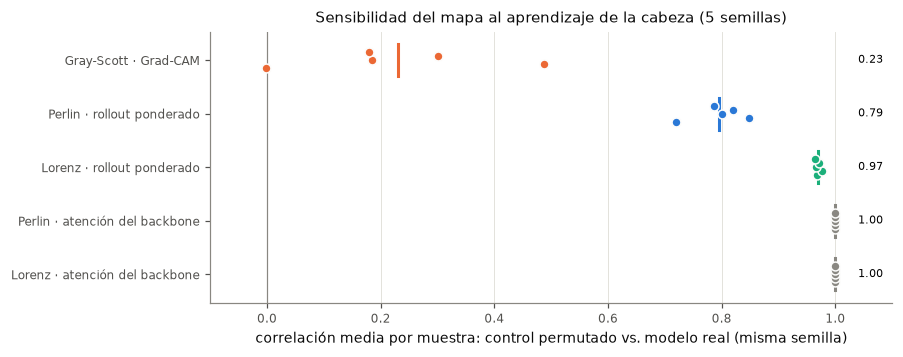

In [4]:
perm = per[per.fase == 'control_permutacion'].copy()
perm['etiqueta'] = [f"{style.TECH_LABEL[t]} · {METHOD[t] if m == 'map' else 'atención del backbone'}"
                    for t, m in zip(perm.technique, perm.mapa)]
orden = [f'{style.TECH_LABEL[t]} · {METHOD[t]}' for t in TECHS] + \
        [f'{style.TECH_LABEL[t]} · atención del backbone' for t in ('perlin', 'lorenz')]
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, lab in enumerate(reversed(orden)):
    d = perm[perm.etiqueta == lab]
    tech = d.technique.iloc[0]
    color = style.TECH_COLOR[tech] if 'backbone' not in lab else style.MUTED
    ax.scatter(d.corr_con_real, np.full(len(d), i) + np.linspace(-0.15, 0.15, len(d)), s=34, color=color,
               edgecolors=style.SURFACE, linewidths=1, zorder=3)
    ax.plot([d.corr_con_real.mean()] * 2, [i - 0.3, i + 0.3], color=color, lw=2)
    ax.text(1.04, i, f'{d.corr_con_real.mean():.2f}', va='center', fontsize=style.FONT_SIZES['annot'])
ax.set_yticks(range(len(orden))); ax.set_yticklabels(list(reversed(orden)))
ax.set_xlim(-0.1, 1.1); ax.axvline(0, color=style.MUTED, lw=0.8); ax.grid(axis='x')
ax.set_xlabel('correlación media por muestra: control permutado vs. modelo real (misma semilla)')
ax.set_title('Sensibilidad del mapa al aprendizaje de la cabeza (5 semillas)')
style.save(fig, FIG / 'permutado_vs_real')
plt.show()

## Figura 3. Modelo real frente a control permutado, mapas medios

Mapa medio en prueba, sobre todas las muestras, del modelo real y del control permutado (media de cinco semillas), con la misma escala por fila. En Gray-Scott se ve cuánto cambia Grad-CAM; en los ViT, cuánto se parece el *rollout* ponderado de un control que no aprendió la etiqueta al del modelo real.

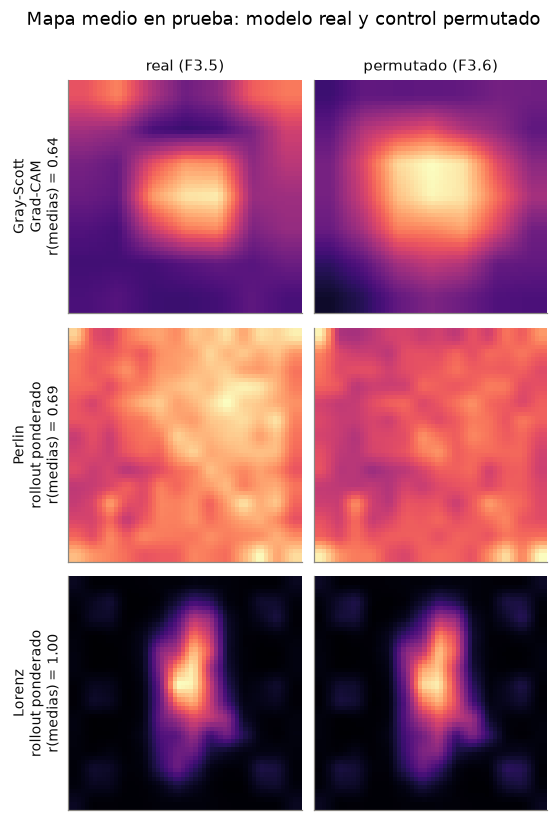

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(5.2, 7.4))
for i, tech in enumerate(TECHS):
    real = (mean_map(tech, 'final', 'map', 'test', 0) * 70 + mean_map(tech, 'final', 'map', 'test', 1) * 44) / 114
    ctrl = (mean_map(tech, 'control_permutacion', 'map', 'test', 0) * 70 +
            mean_map(tech, 'control_permutacion', 'map', 'test', 1) * 44) / 114
    vmax = max(real.max(), ctrl.max())
    for j, (m, t) in enumerate(((real, 'real (F3.5)'), (ctrl, 'permutado (F3.6)'))):
        axes[i, j].imshow(m, cmap='magma', vmin=0, vmax=vmax)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(t)
    r = np.corrcoef(real.ravel(), ctrl.ravel())[0, 1]
    axes[i, 0].set_ylabel(f'{style.TECH_LABEL[tech]}\n{METHOD[tech]}\nr(medias) = {r:.2f}', fontsize=style.FONT_SIZES['label'])
fig.suptitle('Mapa medio en prueba: modelo real y control permutado', y=1.0)
fig.tight_layout()
style.save(fig, FIG / 'real_vs_permutado_medias')
plt.show()

## Concentración y mapas constantes

Entropía media del mapa (bits; 11.61 = uniforme en 56 × 56) y fracción de la masa en el 10 % de píxeles más altos (0.10 = uniforme). Grad-CAM aplica ReLU, así que si ninguna activación de la última capa favorece la clase depresiva, el mapa queda en cero (`frac_constantes`).

In [6]:
per.pivot_table(index=['technique', 'mapa'], columns='fase',
                values=['frac_constantes', 'entropia_media', 'masa_top10']).round(3)

entropia_media             frac_constantes  \
fase                    control_permutacion   final control_permutacion   
technique  mapa                                                           
gray_scott map                       10.353  10.251               0.001   
lorenz     backbone_map              11.057  11.057               0.000   
           map                        9.962   9.870               0.000   
perlin     backbone_map              10.998  10.998               0.000   
           map                       11.341  11.379               0.000   

                                        masa_top10         
fase                     final control_permutacion  final  
technique  mapa                                            
gray_scott map           0.115               0.448  0.464  
lorenz     backbone_map  0.000               0.374  0.374  
           map           0.000               0.637  0.658  
perlin     backbone_map  0.000               0.377  0.377  
           map           0.000               0.252  0.233